# Análise Exploratória de Dados: Custos de Seguro de Saúde

**Disciplina:** Análise e Visualização de Dados  
**Dataset:** *Medical Cost Personal Datasets* (Kaggle)  
**Autor(a):** Galileu Calaça Menezes de Moraes  
**Data:** 15/09/2026

## Objetivo e perguntas

Esta EDA investiga como idade, IMC, número de filhos, tabagismo, sexo e região se relacionam com os custos anuais de seguro médico. Não é uma análise causal nem um modelo preditivo.

1. Como os custos se distribuem e existem outliers relevantes?
2. Os custos parecem diferentes entre fumantes e não fumantes?
3. Quais variáveis numéricas se relacionam mais com os custos?
4. A proporção de custos altos muda entre sexo e faixas etárias?


## Fonte e reprodutibilidade

O conjunto é público no [Kaggle — Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance). O código usa a API pública do Kaggle para permitir a execução no Google Colab sem upload manual. Os valores são custos individuais e não permitem diagnosticar pessoas ou afirmar causalidade.

## Setup e carregamento

In [ ]:
import zipfile
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import entropy

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (12, 5)
COR_NEUTRA, COR_CONTEXTO, COR_DESTAQUE, COR_ALERTA = 'lightgray', '#e9d4d0', '#2d223a', 'tab:red'
PALETA_FUMANTE = {'Não': COR_CONTEXTO, 'Sim': COR_DESTAQUE}

url = 'https://www.kaggle.com/api/v1/datasets/download/mirichoi0218/insurance'
arquivo_zip, arquivo_csv = Path('insurance_kaggle.zip'), Path('insurance.csv')
if not arquivo_csv.exists():
    if not arquivo_zip.exists():
        urlretrieve(url, arquivo_zip)
    with zipfile.ZipFile(arquivo_zip) as z:
        z.extract('insurance.csv')
df_bruto = pd.read_csv(arquivo_csv)
df_bruto.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 1. Princípio estrutural

Começamos por dimensão, tipos, ausências e duplicidades. As colunas são renomeadas para português porque serão usadas no texto e nas visualizações; o significado dos campos é preservado.

In [ ]:
print(f'Dimensão inicial: {df_bruto.shape[0]} linhas e {df_bruto.shape[1]} colunas')
df_bruto.info()
display(df_bruto.describe(include='all').T)
print(f'Duplicadas exatas: {df_bruto.duplicated().sum()}')

renomear = {'age':'idade', 'sex':'sexo', 'bmi':'imc', 'children':'filhos', 'smoker':'fumante', 'region':'regiao', 'charges':'custo'}
df = df_bruto.rename(columns=renomear).copy()
df['sexo'] = df['sexo'].map({'female':'Feminino', 'male':'Masculino'})
df['fumante'] = df['fumante'].map({'yes':'Sim', 'no':'Não'})
df['regiao'] = df['regiao'].str.title()
df_antes = df.copy()
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplicatas removidas: {len(df_antes) - len(df)}')
df.head()


Dimensão inicial: 1338 linhas e 7 colunas
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.04996,18.0,27.0,39.0,51.0,64.0
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.96,26.29625,30.4,34.69375,53.13
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0,0.0,1.0,2.0,5.0
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


Duplicadas exatas: 1
Duplicatas removidas: 1


,idade,sexo,imc,filhos,fumante,regiao,custo
0,19,Feminino,27.900,0,Sim,Southwest,16884.92400
1,18,Masculino,33.770,1,Não,Southeast,1725.55230
2,28,Masculino,33.000,3,Não,Southeast,4449.46200
3,33,Masculino,22.705,0,Não,Northwest,21984.47061
4,32,Masculino,28.880,0,Não,Northwest,3866.85520


**Justificativa:** linhas integralmente duplicadas foram removidas, pois não constituem observações independentes. Nenhuma coluna foi excluída: todas são documentadas na fonte e pertinentes às perguntas da análise.

## 2. Dados faltantes

A seguir, verificamos ausências codificadas como NaN. Como controle complementar, conferimos zeros em idade, IMC e custo, pois eles seriam implausíveis. Já filhos igual a zero é um valor válido.

In [ ]:
ausentes = df.isna().sum().rename('n_ausentes').to_frame()
display(ausentes)
zeros = (df[['idade', 'imc', 'filhos', 'custo']] == 0).sum().rename('n_zeros').to_frame()
display(zeros)
if ausentes['n_ausentes'].sum() == 0:
    print('Não há valores ausentes; não foi necessária imputação nem exclusão por ausência.')


,n_ausentes
idade,0
sexo,0
imc,0
filhos,0
fumante,0
regiao,0
custo,0


,n_zeros
idade,0
imc,0
filhos,573
custo,0


Não há valores ausentes; não foi necessária imputação nem exclusão por ausência.


**Decisão:** não há valores ausentes nem zeros implausíveis nas variáveis contínuas. Logo, imputar ou remover registros seria uma alteração sem fundamento. Como não há ausências, não se aplica investigar mecanismos MCAR, MAR ou MNAR.

## 3. Princípio distribucional antes do tratamento

Custo é a variável de interesse. Idade e IMC são contínuas; filhos é uma contagem discreta e aparecerá nas relações, mas não será tratada como variável contínua no diagnóstico de normalidade.

,count,mean,std,min,25%,mediana,75%,max,assimetria,curtose
idade,1338.0,39.21,14.05,18.00,27.00,39.00,51.00,64.00,0.06,-1.25
imc,1338.0,30.66,6.10,15.96,26.30,30.40,34.69,53.13,0.28,-0.05
custo,1338.0,13270.42,12110.01,1121.87,4740.29,9382.03,16639.91,63770.43,1.52,1.61


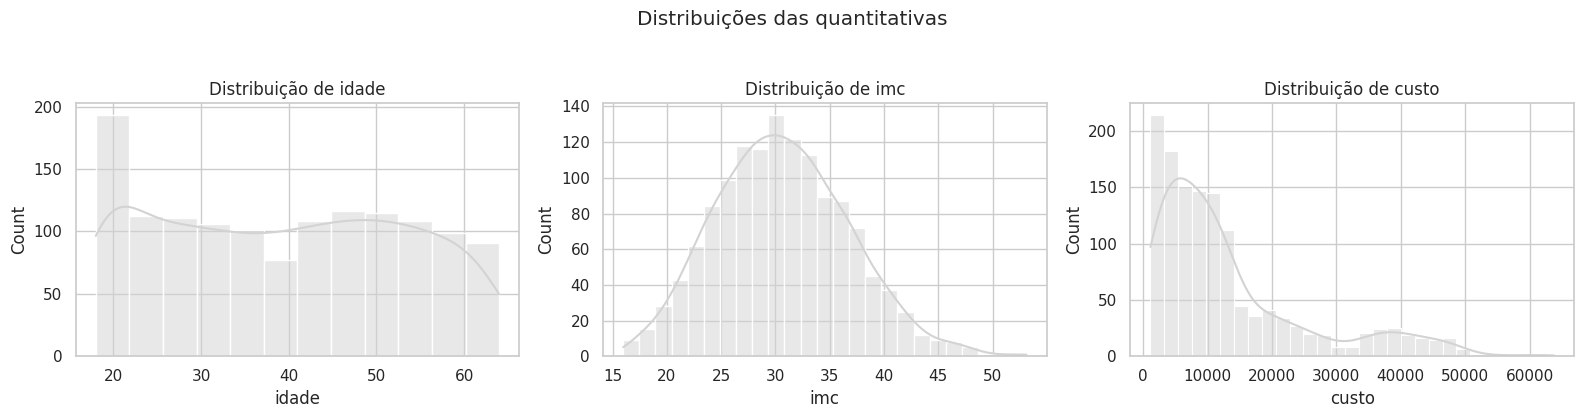

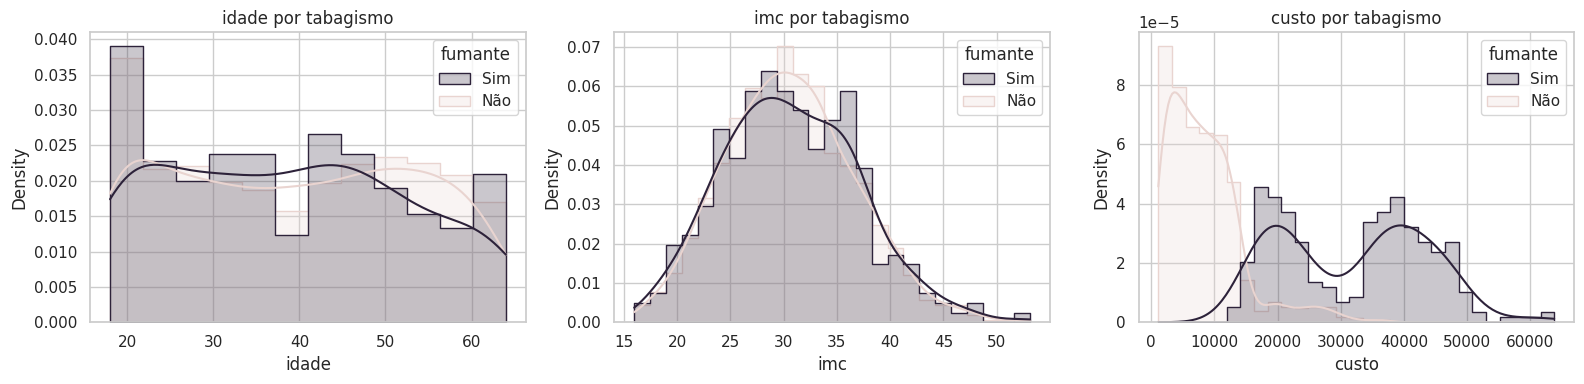

In [ ]:
VARS_QUANT = ['idade', 'imc', 'custo']
VARS_QUALI = ['sexo', 'fumante', 'regiao']
desc_antes = df_antes[VARS_QUANT].describe().T
desc_antes['assimetria'] = df_antes[VARS_QUANT].skew()
desc_antes['curtose'] = df_antes[VARS_QUANT].kurtosis()
display(desc_antes.rename(columns={'50%':'mediana'}).round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=ax)
    ax.set_title(f'Distribuição de {col}')
fig.suptitle('Distribuições das quantitativas', y=1.04)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, VARS_QUANT):
    sns.histplot(data=df, x=col, hue='fumante', kde=True, palette=PALETA_FUMANTE, element='step', stat='density', common_norm=False, ax=ax)
    ax.set_title(f'{col} por tabagismo')
plt.tight_layout(); plt.show()


Shapiro-Wilk — custo: estatística=0.8148; p-valor=1.196e-36
Há evidência contra a normalidade (alfa=0,05).


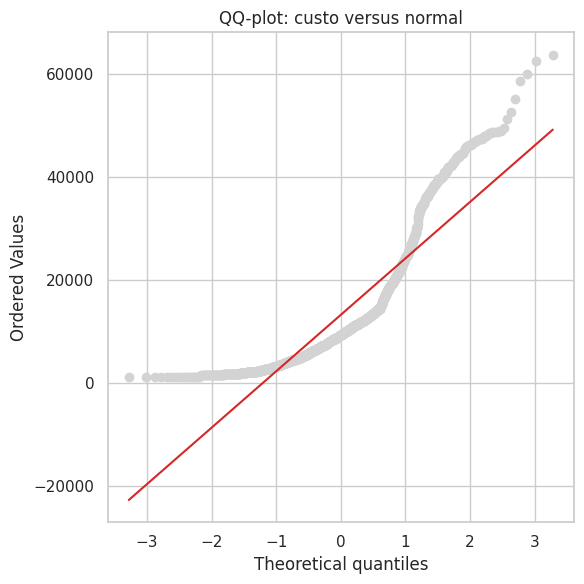

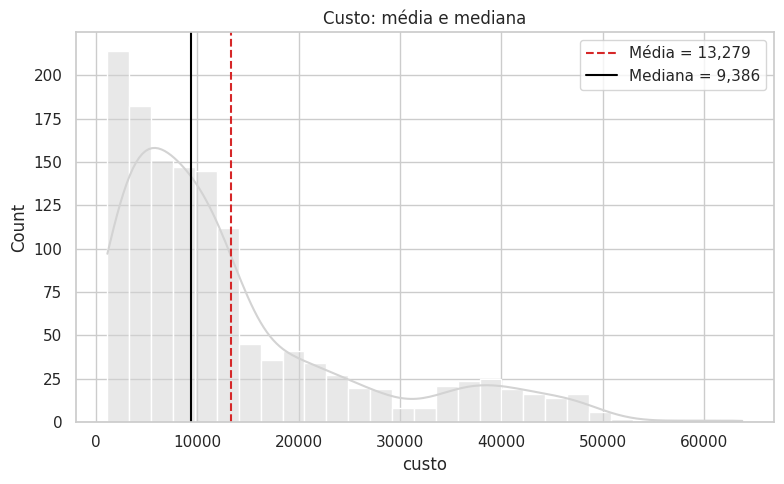

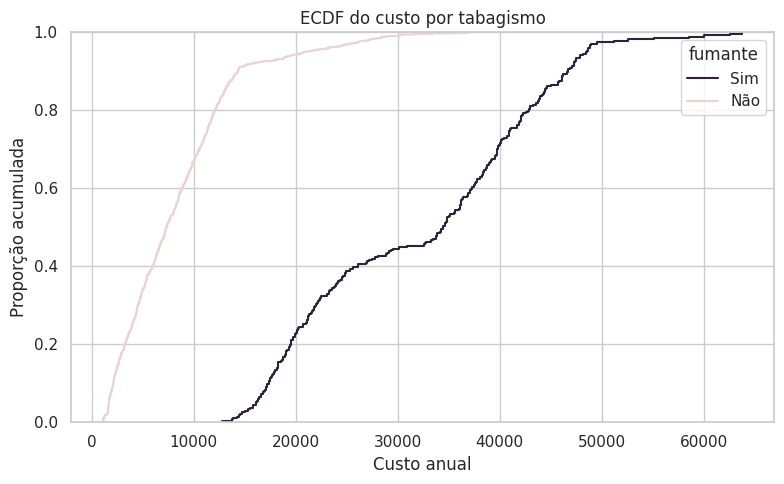

In [ ]:
estatistica_sw, p_sw = stats.shapiro(df['custo'])
print(f'Shapiro-Wilk — custo: estatística={estatistica_sw:.4f}; p-valor={p_sw:.4g}')
print('Há evidência contra a normalidade (alfa=0,05).' if p_sw < .05 else 'Não há evidência suficiente contra a normalidade (alfa=0,05).')
fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df['custo'], dist='norm', plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA); ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA); ax.set_title('QQ-plot: custo versus normal')
plt.tight_layout(); plt.show()

media, mediana = df['custo'].mean(), df['custo'].median()
plt.figure(figsize=(8, 5)); sns.histplot(data=df, x='custo', kde=True, color=COR_NEUTRA)
plt.axvline(media, color=COR_ALERTA, linestyle='--', label=f'Média = {media:,.0f}')
plt.axvline(mediana, color='black', label=f'Mediana = {mediana:,.0f}')
plt.title('Custo: média e mediana'); plt.legend(); plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 5)); sns.ecdfplot(data=df, x='custo', hue='fumante', palette=PALETA_FUMANTE)
plt.title('ECDF do custo por tabagismo'); plt.xlabel('Custo anual'); plt.ylabel('Proporção acumulada')
plt.tight_layout(); plt.show()


**Leitura:** se a média superar a mediana e o histograma exibir cauda à direita, poucos custos muito altos estão puxando a média. O QQ-plot e Shapiro-Wilk complementam a inspeção visual. Este teste é apenas descritivo e não substitui os gráficos.

### Testes de aderência para as variáveis contínuas

O Shapiro-Wilk é aplicado também a idade e IMC. Com aproximadamente 1.300 registros, p-valores muito baixos podem detectar até desvios pequenos; por isso, a decisão é sempre apoiada por histogramas e QQ-plots, nunca pelo teste isolado.

,estatistica,p_valor,rejeita_normalidade
variavel,,,
idade,0.94486,0.00000,True
imc,0.99388,0.00003,True
custo,0.81476,0.00000,True


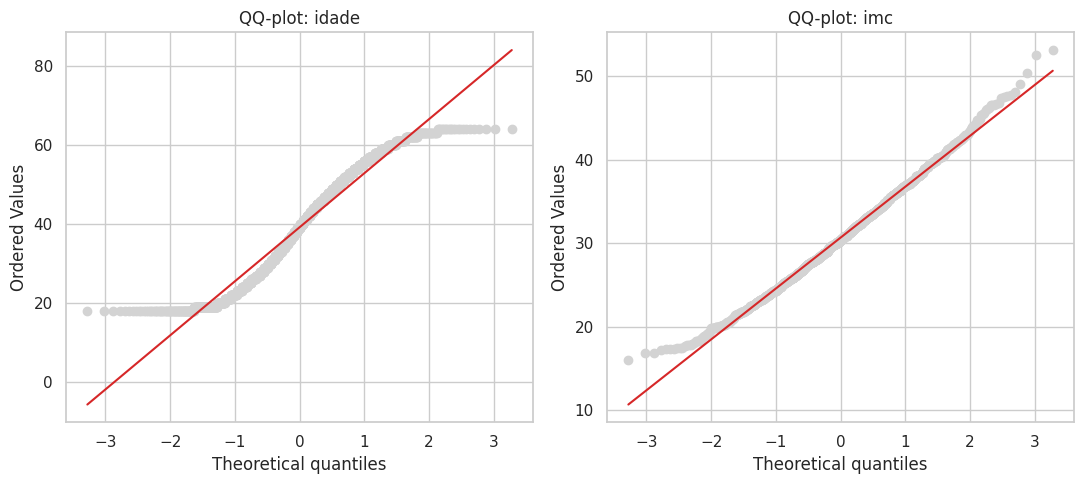

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    estatistica, p_valor = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({'variavel': col, 'estatistica': estatistica, 'p_valor': p_valor, 'rejeita_normalidade': p_valor < .05})
display(pd.DataFrame(resultados_shapiro).set_index('variavel').round(5))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, col in zip(axes, ['idade', 'imc']):
    stats.probplot(df[col], dist='norm', plot=ax)
    ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA); ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
    ax.get_lines()[1].set_color(COR_ALERTA); ax.set_title(f'QQ-plot: {col}')
plt.tight_layout(); plt.show()


### Tendência central e dispersão

A tabela reúne medidas centrais e de dispersão. Em distribuições assimétricas, média e desvio padrão são sensíveis à cauda; mediana e IQR tornam a leitura mais robusta.

,media,mediana,variancia,desvio_padrao,IQR
idade,39.22,39.00,1.972400e+02,14.04,24.00
imc,30.66,30.40,3.722000e+01,6.10,8.41
custo,13279.12,9386.16,1.466608e+08,12110.36,11911.37


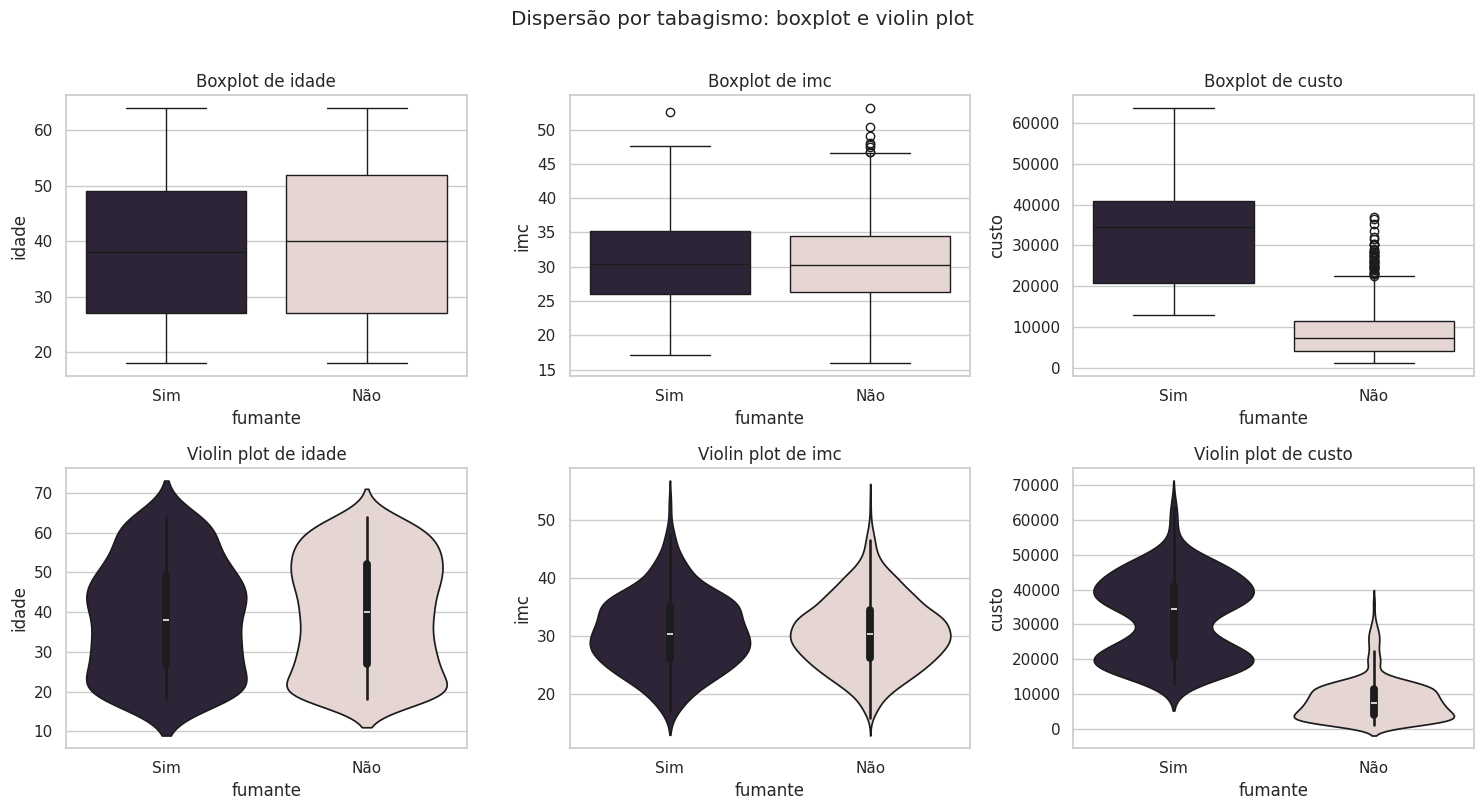

In [ ]:
resumo_disp = pd.DataFrame({
    'media': df[VARS_QUANT].mean(),
    'mediana': df[VARS_QUANT].median(),
    'variancia': df[VARS_QUANT].var(),
    'desvio_padrao': df[VARS_QUANT].std(),
    'IQR': df[VARS_QUANT].quantile(.75) - df[VARS_QUANT].quantile(.25)
})
display(resumo_disp.round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x='fumante', y=col, hue='fumante', palette=PALETA_FUMANTE, legend=False, ax=axes[0, i])
    axes[0, i].set_title(f'Boxplot de {col}')
    sns.violinplot(data=df, x='fumante', y=col, hue='fumante', palette=PALETA_FUMANTE, legend=False, ax=axes[1, i])
    axes[1, i].set_title(f'Violin plot de {col}')
fig.suptitle('Dispersão por tabagismo: boxplot e violin plot', y=1.01)
plt.tight_layout(); plt.show()


## 4. Outliers e decisão de tratamento

A regra do IQR identifica observações estatisticamente incomuns, mas não demonstra erro de dados. Valores altos de custo podem ser legítimos em despesas médicas; por isso, a decisão será conservadora.

,variavel,limite_inferior,limite_superior,n_outliers
0,idade,-9.00,87.00,0
1,imc,13.67,47.32,9
2,custo,-13120.72,34524.78,139


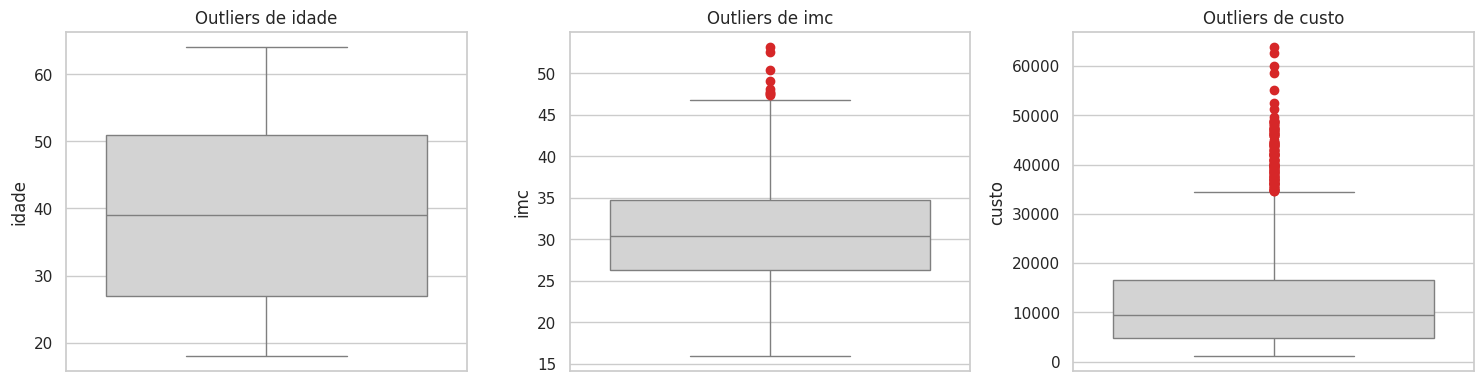

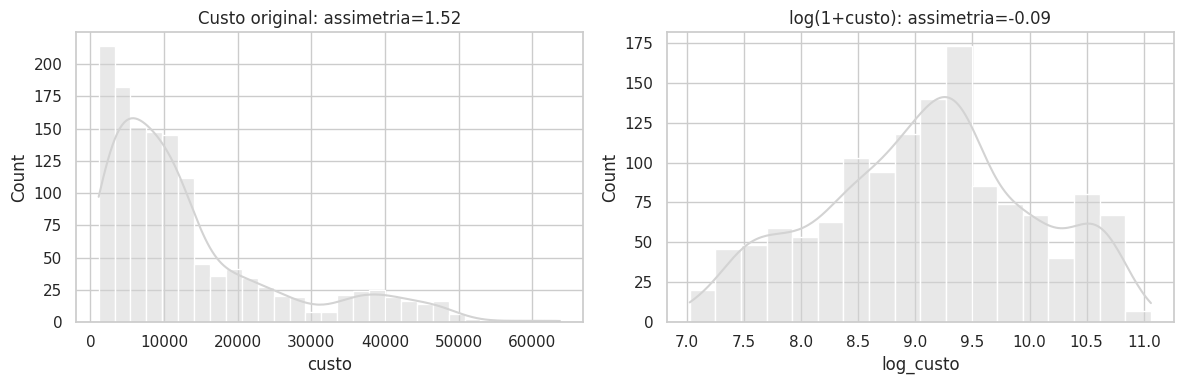

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([.25, .75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

linhas = []
for col in VARS_QUANT:
    inf, sup = limites_iqr(df[col])
    n = ((df[col] < inf) | (df[col] > sup)).sum()
    linhas.append([col, inf, sup, n])
outliers = pd.DataFrame(linhas, columns=['variavel','limite_inferior','limite_superior','n_outliers'])
display(outliers.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA, flierprops={'markerfacecolor': COR_ALERTA, 'markeredgecolor': COR_ALERTA}, ax=ax)
    ax.set_title(f'Outliers de {col}')
plt.tight_layout(); plt.show()

df['log_custo'] = np.log1p(df['custo'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x='custo', kde=True, color=COR_NEUTRA, ax=axes[0]); axes[0].set_title(f'Custo original: assimetria={df.custo.skew():.2f}')
sns.histplot(data=df, x='log_custo', kde=True, color=COR_NEUTRA, ax=axes[1]); axes[1].set_title(f'log(1+custo): assimetria={df.log_custo.skew():.2f}')
plt.tight_layout(); plt.show()


**Decisão:** os outliers de custo e IMC são mantidos, pois são plausíveis e a fonte não aponta erro de digitação. Excluí-los apagaria valores importantes para entender a variabilidade. A transformação logarítmica é somente um diagnóstico de assimetria; as conclusões usam o custo original.

## 5. Estatística descritiva depois do tratamento

A única intervenção foi remover duplicata(s); não houve imputação nem remoção de outliers. A comparação confirma o efeito desse tratamento mínimo.

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois['assimetria'] = df[VARS_QUANT].skew(); desc_depois['curtose'] = df[VARS_QUANT].kurtosis()
display(desc_depois.rename(columns={'50%':'mediana'}).round(2))
comparacao = pd.DataFrame({'assimetria_antes': desc_antes['assimetria'], 'assimetria_depois': desc_depois['assimetria'], 'curtose_antes': desc_antes['curtose'], 'curtose_depois': desc_depois['curtose']})
comparacao['delta_assimetria'] = comparacao['assimetria_depois'] - comparacao['assimetria_antes']
display(comparacao.round(4))


,count,mean,std,min,25%,mediana,75%,max,assimetria,curtose
idade,1337.0,39.22,14.04,18.00,27.00,39.00,51.00,64.00,0.05,-1.24
imc,1337.0,30.66,6.10,15.96,26.29,30.40,34.70,53.13,0.28,-0.05
custo,1337.0,13279.12,12110.36,1121.87,4746.34,9386.16,16657.72,63770.43,1.52,1.60


,assimetria_antes,assimetria_depois,curtose_antes,curtose_depois,delta_assimetria
idade,0.0557,0.0548,-1.2451,-1.2444,-0.0009
imc,0.2840,0.2839,-0.0507,-0.0529,-0.0001
custo,1.5159,1.5154,1.6063,1.6042,-0.0005


### Comparação visual antes × depois

Como apenas duplicata(s) foram removidas, espera-se que as curvas fiquem quase sobrepostas. Esta verificação torna a decisão de tratamento auditável em vez de apenas afirmá-la.

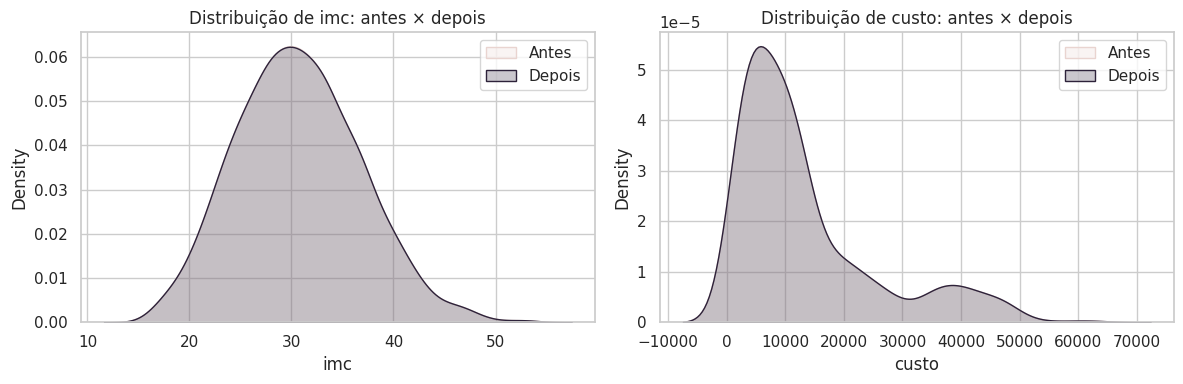

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['imc', 'custo']):
    sns.kdeplot(data=df_antes, x=col, fill=True, color=COR_CONTEXTO, label='Antes', ax=ax)
    sns.kdeplot(data=df, x=col, fill=True, color=COR_DESTAQUE, label='Depois', ax=ax)
    ax.set_title(f'Distribuição de {col}: antes × depois'); ax.legend()
plt.tight_layout(); plt.show()


**Interpretação:** curvas muito parecidas confirmam que a remoção de duplicata(s) não alterou substancialmente a estrutura das distribuições. Isso é coerente com um tratamento conservador.

## 6. Princípio relacional

A seção reúne frequências e relações entre variáveis. Testes estatísticos bivariados não são incluídos, pois são opcionais nas diretrizes; a interpretação é visual e descritiva.


--- sexo ---


,absoluta,relativa
sexo,,
Masculino,675,0.505
Feminino,662,0.495



--- fumante ---


,absoluta,relativa
fumante,,
Não,1063,0.795
Sim,274,0.205



--- regiao ---


,absoluta,relativa
regiao,,
Southeast,364,0.272
Southwest,325,0.243
Northwest,324,0.242
Northeast,324,0.242



--- faixa_etaria ---


,absoluta,relativa
faixa_etaria,,
41–55,421,0.315
26–40,395,0.295
18–25,305,0.228
56+,216,0.162



--- custo_alto ---


,absoluta,relativa
custo_alto,,
Alto,669,0.5
Baixo,668,0.5


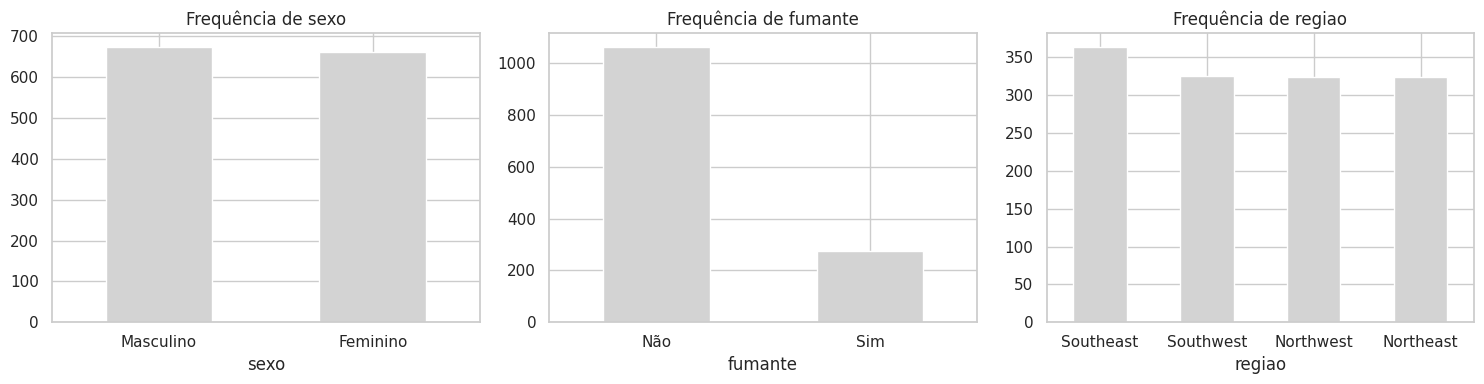

,n_classes,razao_desbalanceamento,entropia_normalizada
sexo,2.0,1.020,1.000
fumante,2.0,3.880,0.732
regiao,4.0,1.123,0.999
faixa_etaria,4.0,1.949,0.978
custo_alto,2.0,1.001,1.000


In [ ]:
df['faixa_etaria'] = pd.cut(df['idade'], bins=[0, 25, 40, 55, 100], labels=['18–25', '26–40', '41–55', '56+'])
df['custo_alto'] = np.where(df['custo'] >= df['custo'].median(), 'Alto', 'Baixo')
VARS_QUALI_ANALISE = VARS_QUALI + ['faixa_etaria', 'custo_alto']
for col in VARS_QUALI_ANALISE:
    freq = pd.concat([df[col].value_counts().rename('absoluta'), df[col].value_counts(normalize=True).rename('relativa')], axis=1)
    print(f'\n--- {col} ---'); display(freq.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, VARS_QUALI):
    df[col].value_counts().plot(kind='bar', color=COR_NEUTRA, ax=ax)
    ax.set_title(f'Frequência de {col}'); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

def metrica_desbalanceamento(serie):
    c = serie.value_counts(); p = c / c.sum()
    return pd.Series({'n_classes':len(c), 'razao_desbalanceamento':c.max()/c.min(), 'entropia_normalizada':entropy(p, base=2)/np.log2(len(c))})
display(pd.DataFrame({c: metrica_desbalanceamento(df[c]) for c in VARS_QUALI_ANALISE}).T.round(3))


### Análise bivariada

A seguir, observamos relações quantitativa × quantitativa, quantitativa × qualitativa e qualitativa × qualitativa. Pearson, Spearman e Kendall foram apresentados na aula; como custo é assimétrico, Spearman é especialmente útil como complemento à correlação linear de Pearson.

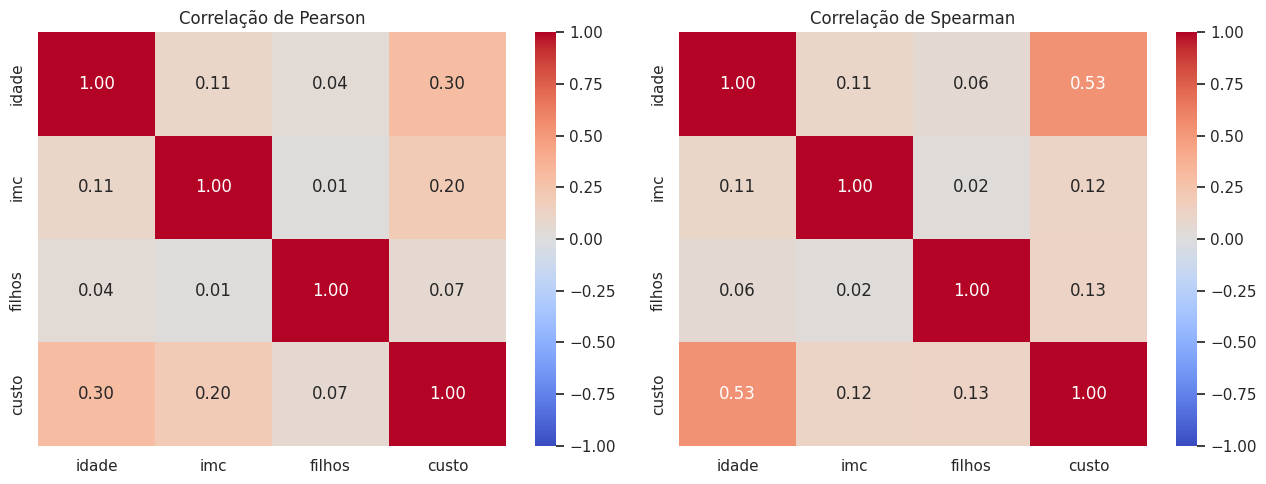

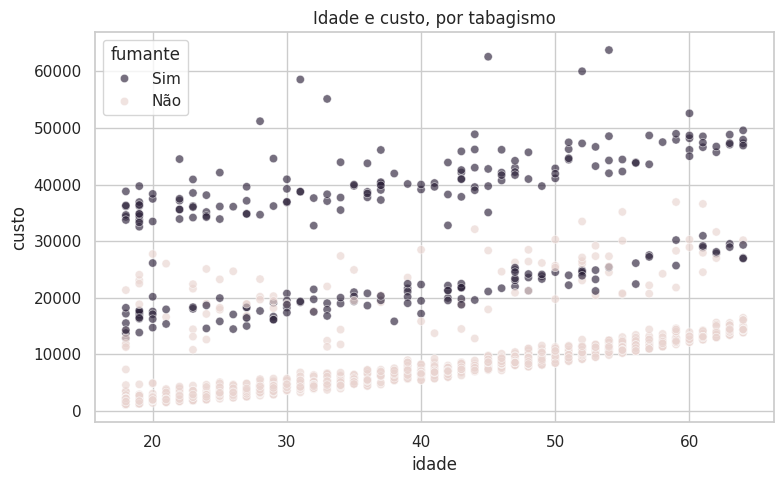

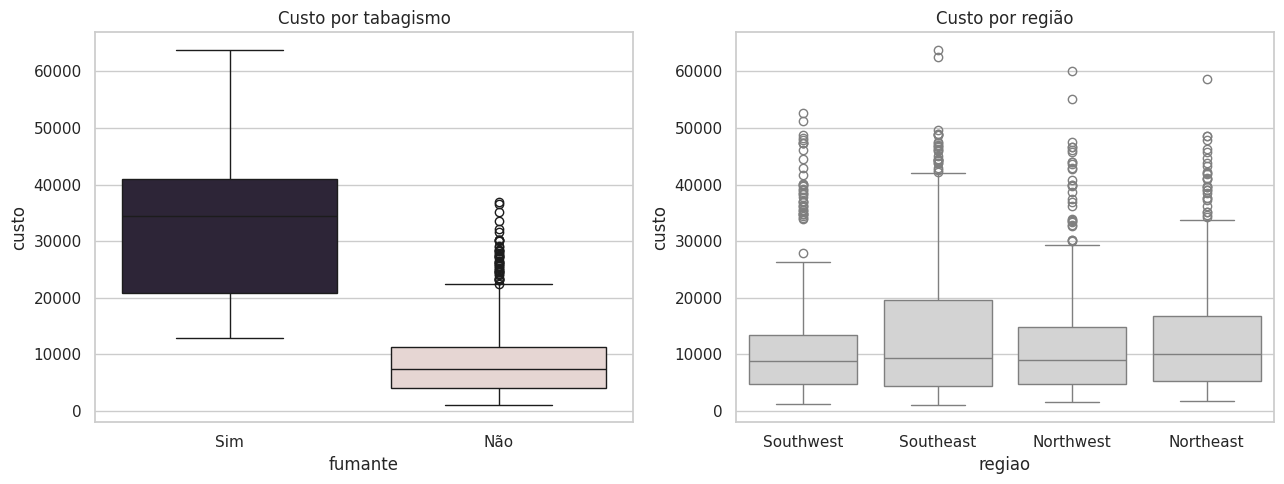

custo_alto,Alto,Baixo
fumante,,
Não,395,668
Sim,274,0


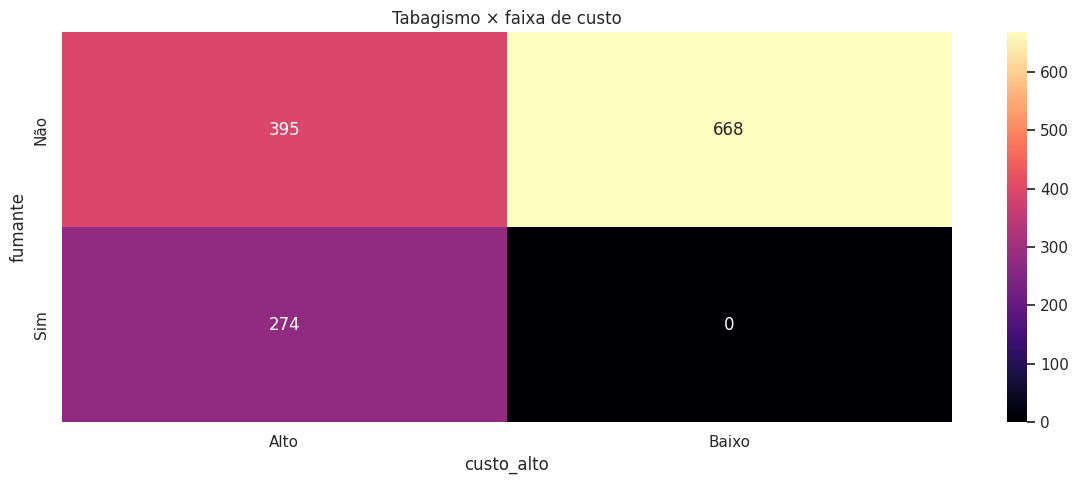

In [ ]:
numericas = ['idade', 'imc', 'filhos', 'custo']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(df[numericas].corr(method='pearson'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0]); axes[0].set_title('Correlação de Pearson')
sns.heatmap(df[numericas].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1]); axes[1].set_title('Correlação de Spearman')
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 5)); sns.scatterplot(data=df, x='idade', y='custo', hue='fumante', palette=PALETA_FUMANTE, alpha=.65)
plt.title('Idade e custo, por tabagismo'); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x='fumante', y='custo', hue='fumante', palette=PALETA_FUMANTE, legend=False, ax=axes[0]); axes[0].set_title('Custo por tabagismo')
sns.boxplot(data=df, x='regiao', y='custo', color=COR_NEUTRA, ax=axes[1]); axes[1].set_title('Custo por região')
plt.tight_layout(); plt.show()

contingencia = pd.crosstab(df['fumante'], df['custo_alto']); display(contingencia)
sns.heatmap(contingencia, annot=True, fmt='d', cmap='magma'); plt.title('Tabagismo × faixa de custo'); plt.tight_layout(); plt.show()


### Fairness e outliers bivariados

Sexo e idade são atributos sensíveis em muitos contextos. A comparação abaixo é somente exploratória: diferenças não provam discriminação, porque a base não contém informações clínicas, cobertura ou acesso suficientes para explicar o custo.

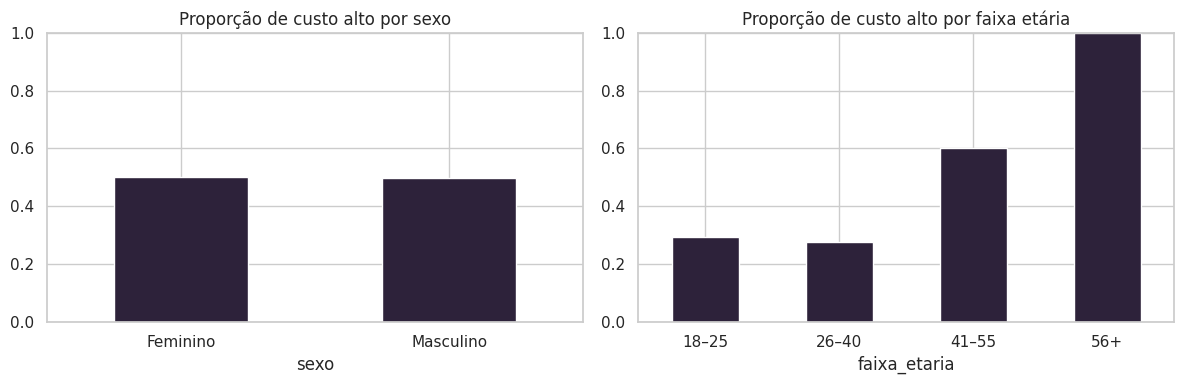

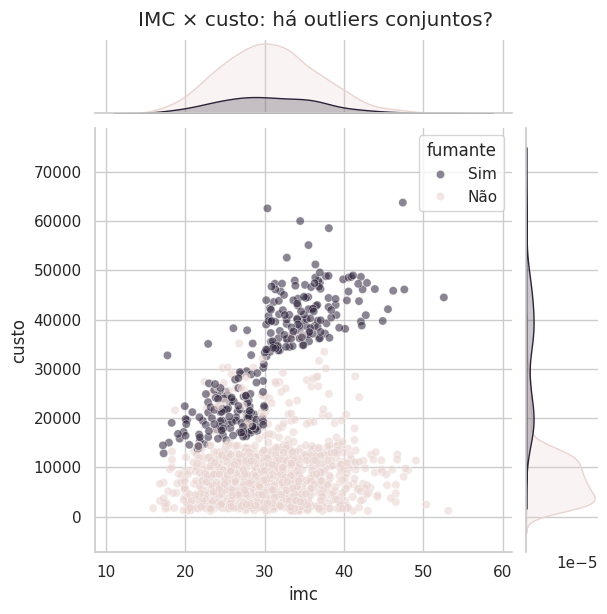

In [ ]:
prop_sexo = pd.crosstab(df['sexo'], df['custo_alto'], normalize='index')
prop_idade = pd.crosstab(df['faixa_etaria'], df['custo_alto'], normalize='index')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
prop_sexo['Alto'].plot(kind='bar', color=COR_DESTAQUE, ax=axes[0]); axes[0].set_title('Proporção de custo alto por sexo'); axes[0].set_ylim(0,1); axes[0].tick_params(axis='x', rotation=0)
prop_idade['Alto'].plot(kind='bar', color=COR_DESTAQUE, ax=axes[1]); axes[1].set_title('Proporção de custo alto por faixa etária'); axes[1].set_ylim(0,1); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

sns.jointplot(data=df, x='imc', y='custo', hue='fumante', palette=PALETA_FUMANTE, alpha=.55, height=6)
plt.suptitle('IMC × custo: há outliers conjuntos?', y=1.02); plt.show()


### Análise multivariada — correlograma

O correlograma reúne, em uma única visualização, distribuições na diagonal e relações entre pares fora dela. Ele é uma forma de verificar se algum padrão visto isoladamente muda quando se observa mais de uma variável.

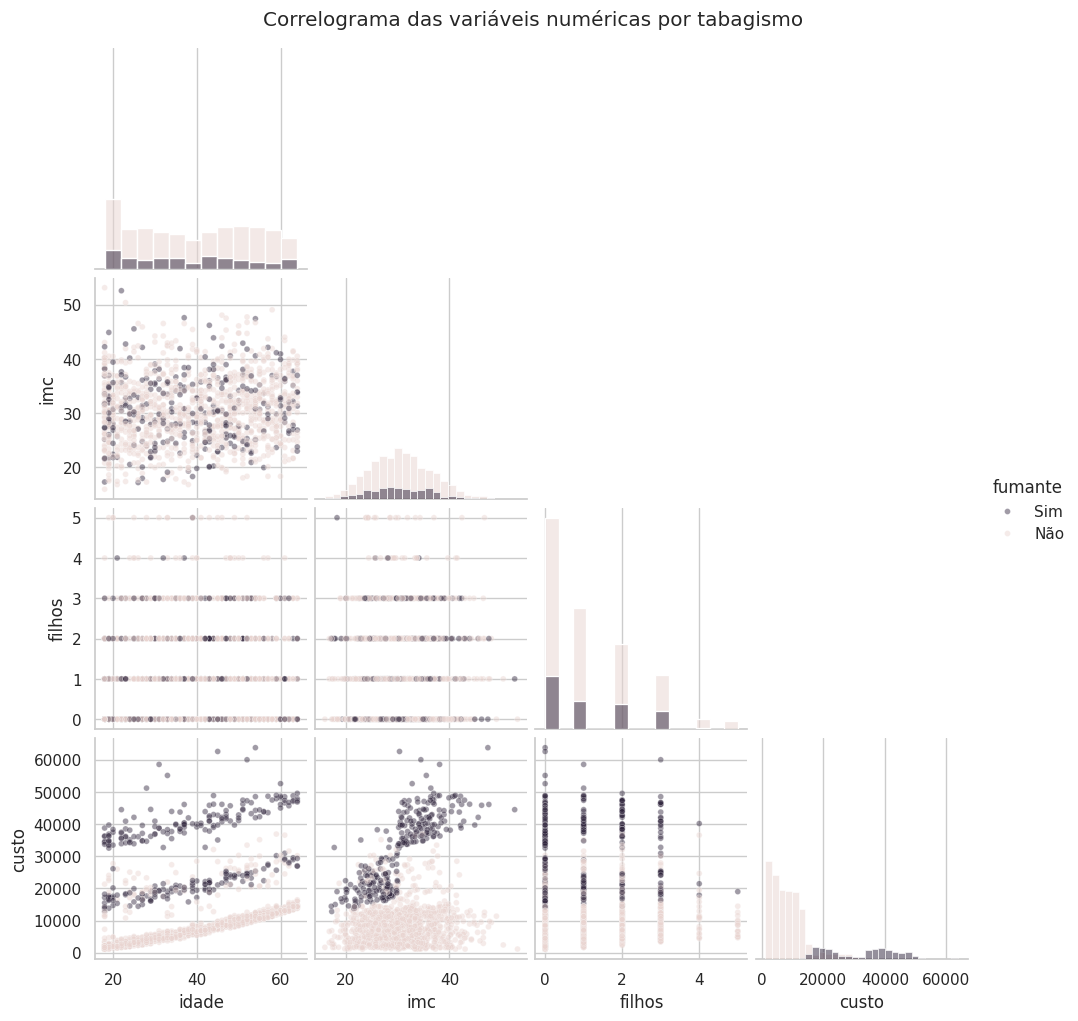

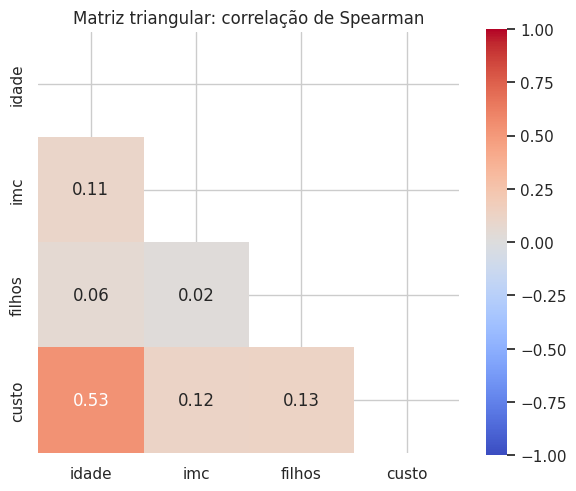

In [ ]:
g = sns.pairplot(df, vars=numericas, hue='fumante', palette=PALETA_FUMANTE,
                 corner=True, diag_kind='hist', plot_kws={'alpha': .45, 's': 18})
g.fig.suptitle('Correlograma das variáveis numéricas por tabagismo', y=1.02)
plt.show()

corr_spearman = df[numericas].corr(method='spearman')
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))
plt.figure(figsize=(6, 5))
sns.heatmap(corr_spearman, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Matriz triangular: correlação de Spearman')
plt.tight_layout(); plt.show()


## Síntese — principais conclusões

1. A distribuição de custo é assimétrica à direita; média, mediana, histogramas, QQ-plot e Shapiro-Wilk devem ser interpretados em conjunto, e a mediana é uma referência robusta.
2. A regra do IQR identifica outliers em custo e IMC. Eles foram mantidos porque são plausíveis e não há evidência de erro de coleta.
3. Os gráficos por tabagismo permitem verificar uma separação relevante na distribuição dos custos e na proporção de custo alto. Trata-se de associação descritiva, não causalidade.
4. Correlações e dispersão sugerem que relações lineares simples não explicam todo o padrão de custo; os grupos de tabagismo ajudam a revelar heterogeneidade.
5. Diferenças por sexo ou faixa etária exigem cautela: podem refletir composição da amostra e fatores ausentes, e não permitem concluir sobre justiça ou injustiça.


## Declaração de uso de IA

Foi utilizada IA generativa (ChatGPT/Codex) como apoio para organizar o roteiro conforme a aula, elaborar e revisar códigos de visualização em Python e revisar a redação. O conteúdo foi adaptado ao dataset escolhido e deve ser conferido após execução no Colab. Foram aceitas somente sugestões compatíveis com os resultados do notebook; testes estatísticos bivariados não foram usados porque são opcionais. A interpretação final e a responsabilidade pela entrega são meus.